# 09 — Adaptación a pacientes de HUPA-UCM con N días (E3)

**Objetivo**: repetir la pregunta de la Fase 5 con pacientes realmente nuevos, de otro hospital y
con otro sensor. ¿Ajustar el modelo de OhioT1DM con los primeros 1, 3 o 7 días de cada paciente
mejora al modelo sin adaptar? Es el experimento E3 de la validación externa, tras E1 y E2 (notebook 08).

**Diseño, fijado antes de ejecutar** (`tfm.training.external_adapt`):
- **Modelo base**: el global de Ohio con los 12 pacientes (`20260916-global-bigru`, 3 semillas).
- **Receta y α vienen de Ohio**: se eligen con la tabla de desarrollo de la Fase 5 sobre sus 12
  pliegues. HUPA no tiene tramo de desarrollo propio (5–10 días antes del test), así que de HUPA solo
  se usan los N días de adaptación.
- **Restricción de RMSE preespecificada** (`-rmse`): en Ohio fue un análisis *post hoc*.
- **Test**: el 30 % final del grupo principal (13 pacientes, 47 eventos puntuables), el mismo que E1
  y E2. N = 7 solo para pacientes con ≥ 7 días de adaptación (quedan 10 pacientes y 40 eventos).


In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from tfm.data import hupa
from tfm.eval.compare import (adaptation_curve_frame, load_result, loso_patient_table,
                              personalization_tests)
from tfm.eval.alarm import recall_at_budget, regime_predictions
from tfm.training import external
from tfm.viz.plots import plot_adaptation_curves, save_figure, set_style

set_style()
pd.set_option("display.width", 160)

EXP = {"global": "20261002-hupa-global", "individual": "20261002-hupa-individual",
       "ft": "20261002-hupa-ft", "ft_weighted": "20261002-hupa-ft-ponderada",
       "ft_rmse": "20261002-hupa-ft-rmse", "ft_weighted_rmse": "20261002-hupa-ft-ponderada-rmse"}
LABELS = {"global": "Global de Ohio sin adaptar", "individual": "Individual (solo N días)",
          "ft": "Global + ajuste fino", "ft_weighted": "Global + ajuste fino ponderado"}
HORIZONS = (30, 60)
BUDGET = 1.0

results = {regime: load_result(exp) for regime, exp in EXP.items()}
patients = results["global"]["patients"]
pts7 = results["ft"]["by_days"]["7"]["patients"]
print(len(patients), "pacientes;", "sin 7 días de adaptación:", results["ft"]["excluded_by_days"]["7"])

13 pacientes; sin 7 días de adaptación: ['HUPA0004P', 'HUPA0006P', 'HUPA0024P']


## 1. Recetas y α elegidos en OhioT1DM

In [2]:
rows = []
for regime, r in results.items():
    for n in r["n_days"]:
        c = r["ohio_choices"][f"0|{n}"]  # the same recipe for every seed? checked below
        same = len({r["ohio_choices"][f"{s}|{n}"]["recipe"] for s in r["seeds"]}) == 1
        rows.append({"régimen": regime, "N": n, "receta (semilla 0)": c["recipe"],
                     "misma en las 3 semillas": same,
                     "α 30": c["alpha"]["30"], "α 60": c["alpha"]["60"],
                     "recall desarrollo 30": round(c["dev_recall"]["30"], 3),
                     "RMSE desarrollo 30": round(c["dev_rmse"]["30"], 2)})
pd.DataFrame(rows)

,régimen,N,receta (semilla 0),misma en las 3 semillas,α 30,α 60,recall desarrollo 30,RMSE desarrollo 30
0,global,0,none,True,0.40,0.40,0.384,20.72
1,individual,1,layers=all|lr=0.001|lam=0|epochs=25,True,0.05,0.10,0.377,39.70
2,individual,3,layers=all|lr=0.001|lam=0|epochs=25,True,0.15,0.20,0.525,30.78
3,individual,7,layers=all|lr=0.001|lam=0|epochs=25,True,0.20,0.25,0.505,27.23
4,ft,1,layers=head|lr=0.001|lam=0|epochs=20,False,0.25,0.30,0.561,22.69
5,ft,3,layers=all|lr=0.0003|lam=0|epochs=20,False,0.25,0.30,0.551,22.91
6,ft,7,layers=head|lr=0.001|lam=0|epochs=40,False,0.30,0.30,0.636,20.80
7,ft_weighted,1,layers=all|lr=0.0001|lam=2|epochs=10,False,0.30,0.40,0.597,21.38
8,ft_weighted,3,layers=head|lr=0.0001|lam=10|epochs=40,False,0.40,0.50,0.603,21.08
9,ft_weighted,7,layers=head|lr=0.0003|lam=5|epochs=5,False,0.40,0.50,0.679,20.75


La receta del ajuste fino cambia entre semillas porque cada semilla tiene su propia tabla de
desarrollo; la del individual es la misma en todas. El α del modelo sin adaptar (0,4 / 0,4) es más
estricto que el del *ensemble* de E2 (0,3 / 0,4): sale de la tabla de pliegues LOSO, cuyos modelos
base vieron 11 pacientes, no de la validación del modelo final. Con la restricción de RMSE, las
recetas elegidas son suaves (lr ≤ 3·10⁻⁴, ≤ 10 épocas, casi siempre solo la cabeza) y su α es el
mismo que el del modelo sin adaptar.

## 2. Resultado preespecificado: α de Ohio

In [3]:
frame = adaptation_curve_frame(results)
clarke = {(reg, int(n), h): b["aggregate"][str(h)]["clarke_AB_pooled"]["mean"]
          for reg, r in results.items() for n, b in r["by_days"].items() for h in HORIZONS}
frame["clarke_AB"] = [clarke[(r.regime, r.n_days, r.horizon_min)] for r in frame.itertuples()]
frame["n_events"] = [results[r.regime]["by_days"][str(r.n_days)]["alarm"][str(r.horizon_min)]["recall"]["n"]
                     for r in frame.itertuples()]
(frame.set_index(["horizon_min", "regime", "n_days"])
 [["rmse_mean", "rmse_std", "recall", "recall_lo", "recall_hi", "false_alarms_per_day",
   "clarke_AB", "n_events"]].sort_index().round(3))

rmse_mean  rmse_std  recall  recall_lo  recall_hi  false_alarms_per_day  clarke_AB  n_events
horizon_min regime           n_days                                                                                              
30          ft               1          20.013     0.907   0.830      0.738      0.922                 1.286     96.199        47
                             3          18.729     0.294   0.865      0.766      0.950                 1.209     97.298        47
                             7          17.344     0.121   0.850      0.742      0.942                 1.138     97.506        40
            ft_rmse          1          18.442     0.094   0.660      0.567      0.759                 0.723     97.488        47
                             3          18.144     0.039   0.787      0.702      0.872                 0.876     97.604        47
                             7          17.470     0.078   0.767      0.658      0.867                 0.948     97.357        40
            ft_weighted      1          19.047     0.696   0.922      0.851      0.986                 1.487     98.240        47
                             3          18.381     0.175   0.887      0.801      0.957                 1.029     98.199        47
                             7          17.807     0.152   0.908      0.825      0.975                 1.164     98.308        40
            ft_weighted_rmse 1          18.513     0.116   0.631      0.518      0.752                 0.632     97.777        47
                             3          18.346     0.123   0.695      0.589      0.801                 0.688     97.984        47
                             7          17.782     0.135   0.792      0.675      0.900                 0.957     98.228        40
            global           0          18.622     0.067   0.631      0.532      0.730                 0.646     97.265        47
            individual       1          43.884     0.476   0.766      0.645      0.879                 1.689     91.795        47
                             3          22.665     0.250   0.950      0.901      0.993                 1.842     97.116        47
                             7          19.265     0.332   0.933      0.867      0.983                 1.966     97.110        40
60          ft               1          35.975     1.300   0.426      0.305      0.553                 1.182     93.026        47
                             3          34.586     0.434   0.482      0.362      0.603                 1.084     93.745        47
                             7          31.202     0.260   0.475      0.333      0.625                 1.060     93.508        40
            ft_rmse          1          34.162     0.221   0.121      0.050      0.206                 0.375     91.952        47
                             3          33.468     0.294   0.199      0.099      0.319                 0.480     92.737        47
                             7          31.089     0.168   0.375      0.250      0.517                 0.802     93.508        40
            ft_weighted      1          34.525     1.035   0.397      0.291      0.518                 1.126     94.125        47
                             3          33.630     0.351   0.362      0.255      0.482                 0.765     94.042        47
                             7          32.239     0.248   0.483      0.375      0.592                 0.991     94.992        40
            ft_weighted_rmse 1          34.191     0.078   0.156      0.071      0.255                 0.431     92.084        47
                             3          33.838     0.447   0.199      0.106      0.312                 0.528     92.580        47
                             7          32.014     0.120   0.275      0.158      0.400                 0.767     94.052        40
            global           0          34.449     0.091   0.085      0.028      0.156                 0.341     91.580        47
       

**Con el α de Ohio, cada régimen acaba en un número distinto de falsas alarmas.** El modelo sin
adaptar se queda en 0,65 FA/día a 30 min (recall 0,631), por debajo del presupuesto de 1. Los
ajustes finos sin restricción lo superan (1,03–1,49) y el individual llega a 1,69–1,97. Leída
sola, esta tabla diría que adaptar mejora mucho la detección, pero buena parte de esa mejora se
paga con más alarmas. Las variantes con restricción de RMSE son las que se quedan cerca del
modelo sin adaptar (0,63–0,96 FA/día).

En error, el individual es el peor con cualquier N (43,88 mg/dL con 1 día). El ajuste fino baja el
RMSE de 18,62 a 17,34 con 7 días, aunque esa fila son 10 pacientes, no 13; la comparación justa es
la pareada por paciente de abajo. Clarke A+B a 30 min se mueve entre el 96,2 % y el 98,3 % en
todos los regímenes, salvo el individual con 1 día (91,8 %).

In [4]:
COMPARISONS = (("ft", "global"), ("ft_weighted", "global"), ("ft_rmse", "global"),
               ("ft_weighted_rmse", "global"), ("individual", "global"), ("ft_weighted", "ft"),
               ("ft", "individual"))
pruebas = personalization_tests(results, comparisons=COMPARISONS)
cols = ["comparison", "n_days", "horizon_min", "metric", "n", "median_diff", "p_value", "p_holm"]
print("Significativas tras Holm (p_holm < 0,05):")
pruebas.loc[pruebas["p_holm"] < 0.05, cols].round(4)

Significativas tras Holm (p_holm < 0,05):


,comparison,n_days,horizon_min,metric,n,median_diff,p_value,p_holm
3,ft vs global,1,60,alarm_recall,13,0.3333,0.0020,0.0371
7,ft vs global,3,60,alarm_recall,13,0.4444,0.0010,0.0205
15,ft_weighted vs global,1,60,alarm_recall,13,0.3333,0.0020,0.0371
19,ft_weighted vs global,3,60,alarm_recall,13,0.3333,0.0010,0.0205
43,ft_weighted_rmse vs global,3,60,alarm_recall,13,0.1111,0.0020,0.0371
48,individual vs global,1,30,rmse,13,25.9020,0.0002,0.0051
50,individual vs global,1,60,rmse,13,30.0761,0.0012,0.0232
55,individual vs global,3,60,alarm_recall,13,0.5556,0.0020,0.0371
72,ft vs individual,1,30,rmse,13,-25.3055,0.0002,0.0051
74,ft vs individual,1,60,rmse,13,-28.4974,0.0002,0.0051


De las 84 comparaciones (7 pares × 3 N × 2 horizontes × 2 métricas; Holm por métrica y horizonte),
sobreviven a Holm dos grupos:

1. **El individual tiene más error**: más que el ajuste fino con 1 y 3 días en los dos horizontes y con
   7 días a 30 min (p_Holm ≤ 0,035), y más que el modelo sin adaptar con 1 día (p_Holm 0,005 y 0,023).
   Es lo mismo que en Ohio.
2. **El recall a 60 min de los regímenes adaptados frente al modelo sin adaptar** (N = 1 y 3,
   p_Holm 0,021–0,037). **No es una mejora de detección**: el modelo sin adaptar trabaja a
   0,34 FA/día a 60 min y esos regímenes a 0,53–1,69. Es el efecto del punto de operación que se
   deshace en la sección 3.

In [5]:
pruebas.loc[pruebas["comparison"].isin(["ft_rmse vs global", "ft_weighted_rmse vs global"])
            & (pruebas["metric"] == "rmse"), cols].round(4)

,comparison,n_days,horizon_min,metric,n,median_diff,p_value,p_holm
24,ft_rmse vs global,1,30,rmse,13,-0.0998,0.0479,0.4785
26,ft_rmse vs global,1,60,rmse,13,-0.1847,0.0942,0.9424
28,ft_rmse vs global,3,30,rmse,13,-0.4003,0.0046,0.0696
30,ft_rmse vs global,3,60,rmse,13,-0.5422,0.0134,0.1746
32,ft_rmse vs global,7,30,rmse,10,-0.6258,0.0039,0.0625
34,ft_rmse vs global,7,60,rmse,10,-2.1648,0.0039,0.0703
36,ft_weighted_rmse vs global,1,30,rmse,13,-0.0448,0.3396,1.0000
38,ft_weighted_rmse vs global,1,60,rmse,13,-0.0929,0.1909,1.0000
40,ft_weighted_rmse vs global,3,30,rmse,13,-0.2234,0.0171,0.2222
42,ft_weighted_rmse vs global,3,60,rmse,13,-0.3061,0.0046,0.0742


**La restricción de RMSE da una mejora pequeña y sistemática del error**: −0,40 y −0,63 mg/dL de
mediana por paciente a 30 min con N = 3 y 7 (p = 0,005 y 0,004), y −2,16 a 60 min con N = 7. Pero
ninguna sobrevive a Holm (p_Holm 0,063–0,074 en las mejores). En Ohio, la misma restricción no
mejoraba nada. Aquí el modelo base sí está fuera de su distribución, y eso deja margen a una
adaptación suave.

## 3. A igual número de falsas alarmas

Para separar detección de número de alarmas, cada régimen se lee con **su propio α, el que más
detecta sin pasar de 1 FA/día sobre el test** (`tfm.eval.alarm.recall_at_budget`; rejilla de α en
pasos de 0,02). **Es una lectura descriptiva, no un resultado**: el α se elige con el test. Pero se
elige igual para todos, así que la comparación entre regímenes es justa. Con N = 7 se compara con el
modelo sin adaptar **sobre los mismos 10 pacientes**.

In [6]:
raw_events = external.events_by_scope(hupa.load_frames())["test"]
events_fn = lambda patient, p: external.scorable(raw_events[patient], p)  # noqa: E731
preds = {regime: regime_predictions(exp, hupa.ALARM_EPISODE_GAP_MIN) for regime, exp in EXP.items()}
matched = pd.concat([recall_at_budget(preds[reg], events_fn, BUDGET).assign(regime=reg)
                     for reg in EXP], ignore_index=True)
# The unadapted model on the ten patients that have seven days, for the N = 7 comparison.
global_7 = recall_at_budget(preds["global"], events_fn, BUDGET, patients=pts7)
assert matched["within_budget"].all() and global_7["within_budget"].all()
(pd.concat([matched, global_7.assign(regime="global (10 pacientes con 7 días)")])
 .set_index(["horizon_min", "regime", "n_days"])
 [["alpha", "recall", "recall_lo", "recall_hi", "false_alarms_per_day", "n_events", "n_patients"]]
 .sort_index().round(3))

alpha  recall  recall_lo  recall_hi  false_alarms_per_day  n_events  n_patients
horizon_min regime                           n_days                                                                                 
30          ft                               1        0.34   0.617      0.511      0.730                 0.973        47          13
                                             3        0.28   0.844      0.745      0.936                 0.994        47          13
                                             7        0.32   0.817      0.700      0.917                 0.974        40          10
            ft_rmse                          1        0.30   0.865      0.794      0.936                 0.973        47          13
                                             3        0.30   0.879      0.794      0.950                 0.994        47          13
                                             7        0.32   0.808      0.692      0.917                 0.957        40          10
            ft_weighted                      1        0.46   0.723      0.617      0.830                 0.966        47          13
                                             3        0.40   0.809      0.716      0.887                 0.945        47          13
                                             7        0.42   0.825      0.725      0.908                 0.966        40          10
            ft_weighted_rmse                 1        0.32   0.851      0.766      0.929                 0.973        47          13
                                             3        0.34   0.830      0.745      0.908                 0.938        47          13
                                             7        0.40   0.792      0.675      0.900                 0.957        40          10
            global                           0        0.28   0.887      0.801      0.951                 0.966        47          13
            global (10 pacientes con 7 días) 0        0.32   0.758      0.650      0.867                 0.922        40          10
            individual                       1        0.26   0.447      0.319      0.574                 0.924        47          13
                                             3        0.32   0.745      0.631      0.844                 0.980        47          13
                                             7        0.36   0.658      0.517      0.783                 0.983        40          10
60          ft                               1        0.36   0.355      0.241      0.482                 0.924        47          13
                                             3        0.30   0.440      0.312      0.567                 0.959        47          13
                                             7        0.32   0.442      0.300      0.592                 0.940        40          10
            ft_rmse                          1        0.28   0.305      0.191      0.440                 0.994        47          13
                                             3        0.30   0.355      0.241      0.482                 0.897        47          13
                                             7        0.32   0.433      0.283      0.584                 0.862        40          10
            ft_weighted                      1        0.44   0.362      0.248      0.489                 0.973        47          13
                                             3        0.40   0.411      0.305      0.532                 0.911        47          13
                                             7        0.46   0.367      0.250      0.500                 0.948        40          10
            ft_weighted_rmse                 1        0.30   0.312      0.199      0.447                 0.931        47          13
                                             3        0.32   0.326      0.213      0.461                 0.897        47          13
                                             7        0.40   0.

**A igual número de falsas alarmas, adaptar no mejora la detección.**
- **A 30 min, 13 pacientes**: el modelo sin adaptar detecta **0,887 (0,801–0,951)**. Ningún régimen
  adaptado lo supera: la restricción de RMSE lo iguala (0,830–0,879) y el ajuste fino sin restricción
  con 1 día lo empeora (0,617; ponderado, 0,723). El individual queda muy por debajo con 1 día
  (0,447).
- **A 30 min con N = 7, 10 pacientes**: el modelo sin adaptar detecta 0,758 (0,650–0,867) y los
  ajustes finos 0,79–0,83. La diferencia (+0,03 a +0,07) cae dentro de los IC.
- **A 60 min** todo queda entre 0,26 y 0,44, con IC que se solapan.

Las cifras E2 del notebook 08 (0,845 en la serie entera) usan el *ensemble* y otro α; aquí son
modelos por semilla y solo el test.

In [7]:
sweep = []
for b in (0.75, 1.0, 1.25, 1.5):
    for reg in ("global", "ft", "ft_weighted", "ft_rmse", "ft_weighted_rmse", "individual"):
        t = recall_at_budget({k: v for k, v in preds[reg].items() if k[1] in (0, 7)},
                             events_fn, b, patients=pts7)
        t = t[t["horizon_min"] == 30].iloc[0]
        sweep.append({"presupuesto FA/día": b, "régimen": reg, "recall": t["recall"]})
(pd.DataFrame(sweep).pivot(index="régimen", columns="presupuesto FA/día", values="recall")
 .round(3))

presupuesto FA/día,0.75,1.00,1.25,1.50
régimen,,,,
ft,0.608,0.817,0.875,0.975
ft_rmse,0.625,0.808,0.925,0.975
ft_weighted,0.583,0.825,0.900,0.967
ft_weighted_rmse,0.608,0.792,0.925,0.992
global,0.567,0.758,0.867,0.950
individual,0.583,0.658,0.758,0.858


La ventaja de los ajustes finos con N = 7 sobre el modelo sin adaptar se mantiene con
cualquier presupuesto (+0,01 a +0,07 a 30 min). Es pequeña y del mismo signo siempre, pero con 40
eventos no es distinguible del ruido. El recall depende mucho del presupuesto (0,57 → 0,95 para el
modelo sin adaptar entre 0,75 y 1,5 FA/día): una tabla con un único presupuesto da una precisión
aparente que no tiene.

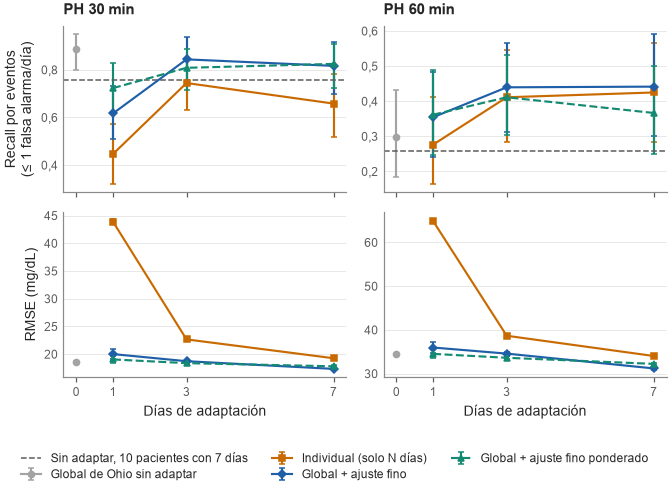

In [8]:
fig_frame = matched.merge(frame[["regime", "n_days", "horizon_min", "rmse_mean", "rmse_std"]],
                          on=["regime", "n_days", "horizon_min"])
refs = {"Sin adaptar, 10 pacientes con 7 días":
        {"recall": dict(zip(global_7["horizon_min"], global_7["recall"]))}}
fig = plot_adaptation_curves(fig_frame, refs, labels=LABELS)
save_figure(fig, "09_hupa_adaptacion")
plt.show()

**Figura 09_hupa_adaptacion.** Arriba, el recall por eventos de cada régimen con su mejor α
sin pasar de 1 FA/día en el test (IC95 % bootstrap, promediado sobre 3 semillas); abajo, el RMSE
(media ± desviación entre semillas). El punto en N = 0 es el modelo sin adaptar sobre los
13 pacientes; la línea discontinua, el mismo modelo sobre los 10 pacientes que tienen 7 días, con
los que se calcula N = 7. A 30 min, ningún régimen adaptado supera al modelo sin adaptar con
1 o 3 días, y el ajuste fino con 1 día queda por debajo. El individual tiene siempre el mayor
error.

In [9]:
t7 = (loso_patient_table(results["ft_rmse"], 7, 30)
      .merge(loso_patient_table(results["global"], 0, 30), on="patient", suffixes=("_ft_rmse", "_global")))
t7["delta_rmse"] = t7["rmse_ft_rmse"] - t7["rmse_global"]
t7[["patient", "rmse_global", "rmse_ft_rmse", "delta_rmse", "n_events_global"]].round(2).sort_values("delta_rmse")

,patient,rmse_global,rmse_ft_rmse,delta_rmse,n_events_global
7,HUPA0022P,13.93,9.66,-4.27,9
0,HUPA0001P,26.94,25.42,-1.51,1
1,HUPA0002P,16.43,15.41,-1.02,7
3,HUPA0005P,16.15,15.32,-0.84,2
8,HUPA0023P,14.10,13.39,-0.71,3
6,HUPA0017P,20.14,19.60,-0.54,1
2,HUPA0003P,17.49,17.01,-0.48,6
4,HUPA0007P,21.62,21.16,-0.46,4
9,HUPA0025P,12.87,12.76,-0.11,6
5,HUPA0016P,19.87,19.96,0.09,1


Con 7 días y la restricción de RMSE, **9 de los 10 pacientes reducen el error** a 30 min. La mayor
mejora es la de **HUPA0022P (−4,27 mg/dL, de 13,93 a 9,66)**: es el paciente que en E1 empeoraba a
la persistencia por sus entradas de tratamiento (notebook 08). La adaptación corrige justo el
desajuste que el diagnóstico atribuía a la población. Con 1–9 eventos por paciente, el recall
individual no se interpreta.

## Conclusiones

1. **En HUPA se repite el resultado de Ohio: con ≤ 7 días, adaptar no mejora la detección del modelo
   sin adaptar.** A igual número de falsas alarmas, el modelo sin adaptar detecta 0,887 a 30 min y
   ningún régimen adaptado lo supera. Con 7 días la diferencia es de +0,03 a +0,07, dentro del IC.
2. **Con el α de Ohio, los regímenes adaptados parecen detectar más, pero es un artefacto del punto
   de operación**: el α elegido en Ohio deja al modelo sin adaptar en 0,65 FA/día y a los ajustados
   por encima de 1. Las diferencias de recall a 60 min que sobreviven a Holm vienen de ahí. **En la
   memoria no se puede presentar un recall sin sus FA/día.**
3. **La restricción de RMSE, preespecificada aquí, da la única mejora consistente**: menos error en
   9 de 10 pacientes con 7 días (−0,63 mg/dL de mediana a 30 min), sin pasar de 1 FA/día.
   Corrige sobre todo a HUPA0022P. No sobrevive a Holm (p_Holm ≥ 0,063).
4. **El modelo individual es el peor en error con cualquier N**, también fuera de Ohio.